# Zimbabwe House Prices: Linear Baseline and Multimodal Deep Learning

This notebook fits two models on the cleaned, deduplicated USD listings: a Ridge-regularized linear regression baseline using structured features and train-only TF-IDF text, and a multimodal neural regressor combining structured features, description embeddings, and house photos. The implementation is in [`src/train_models.py`](../src/train_models.py).

## Architecture and modeling choices

- **Target:** `log1p(price_usd)` reduces the effect of the strongly right-skewed asking prices. Scores are transformed back to USD for interpretation.
- **Split:** a seeded, price-decile-stratified train/validation/test split. Numeric scaling, category levels, text vocabulary, and TF-IDF statistics are learned from training rows only. Duplicate URLs were already consolidated in the cleaning notebook.
- **Linear baseline:** Ridge-regularized linear regression over train-standardized bedrooms/bathrooms/areas, one-hot location/property-type/amenity features, and a compact TF-IDF description representation. Standardized numeric values are clipped to ±10 to limit the effect of extreme area entries. L2 regularization stabilizes correlated and sparse features.
- **Multimodal model:** a frozen ImageNet-pretrained ResNet18 extracts a 512-dimensional CNN feature from each listing photo. A trainable word-embedding branch mean-pools up to 192 description tokens. A structured MLP, text projection, and image projection are concatenated and passed to a fusion MLP. The model starts from the fitted linear baseline and learns a multimodal residual, so early stopping can retain the baseline if extra modalities do not help validation performance.
- **Training:** Smooth L1 loss on log-price, AdamW, gradient clipping, validation-based early stopping, and a fixed seed. The image encoder is frozen to reduce overfitting on this small dataset; only the embedding and fusion layers are trained.
- **Leakage control:** currency-price expressions in text are masked; the target and listing identifiers are not model inputs. The held-out test set is used only for final evaluation.

In [1]:
from pathlib import Path
import sys
from IPython.display import display

HERE = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [HERE, *HERE.parents] if (path / 'reports' / 'eda' / 'cleaned_listings.csv').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run notebooks/01_clean_explore.ipynb first to create reports/eda/cleaned_listings.csv.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.train_models import run_training

results = run_training(PROJECT_ROOT, max_epochs=60, seed=42)
display(results['metrics'])

C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\src\train_models.py:386: UserWarning: 11 of 2618 listings have no readable local photo; their image features are zero-filled.
  image_features, local_image_count = _extract_image_features(listings)


Rows: 2,618; train/validation/test: 1,779/315/524
Listings with a local image: 2,607/2,618
Multimodal best epoch: 9
                                      model      MAE_USD     RMSE_USD  R2_USD  MAE_log
Multimodal ResNet18 + text embeddings + MLP 110,581.0326 241,358.8362  0.5856   0.3095
         Linear Ridge (structured + TF-IDF) 121,780.9583 301,012.6982  0.3555   0.3751
Reports: C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\reports\modeling
Saved models: C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\models\linear_baseline.joblib, C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\models\multimodal_fusion.pt


,model,MAE_USD,RMSE_USD,R2_USD,MAE_log
0,Multimodal ResNet18 + text embeddings + MLP,110581.032562,241358.836216,0.585648,0.309526
1,Linear Ridge (structured + TF-IDF),121780.958277,301012.698246,0.355516,0.375085


## Held-out evaluation

MAE and RMSE are in USD; R² is computed in USD space. Because of the log target, both models optimize a scale-aware loss but are judged in the original price currency. Compare the multimodal model with the linear baseline rather than assuming the neural model must win. The dataset is geographically concentrated and listing photos/descriptions may be incomplete or noisy, so report the split and limitations with any conclusions.

In [2]:
display(results['metrics'].sort_values('MAE_USD'))
display(results['predictions'].head(10))
display(results['history'].tail())
print('\nSaved artifacts:')
for name, path in results['paths'].items():
    print(f'{name}: {path}')

,model,MAE_USD,RMSE_USD,R2_USD,MAE_log
0,Multimodal ResNet18 + text embeddings + MLP,110581.032562,241358.836216,0.585648,0.309526
1,Linear Ridge (structured + TF-IDF),121780.958277,301012.698246,0.355516,0.375085


,listing_id,property_url,actual_price_usd,linear_predicted_price_usd,multimodal_predicted_price_usd
0,170518,https://www.property.co.zw/for-sale/houses-mre...,70000.0,96084.935574,1.092136e+05
1,257406,https://www.property.co.zw/for-sale/houses-phl...,250000.0,260742.434992,2.757688e+05
2,257654,https://www.property.co.zw/for-sale/houses-phl...,300000.0,258077.198319,2.972330e+05
3,253626,https://www.property.co.zw/for-sale/houses-fac...,185000.0,104216.353173,9.160098e+04
4,240389,https://www.property.co.zw/for-sale/houses-sbr...,420000.0,398114.602088,2.039631e+05
5,255992,https://www.property.co.zw/for-sale/townhouses...,150000.0,189683.035073,1.696389e+05
6,238171,https://www.property.co.zw/for-sale/houses-gnr...,850000.0,728941.446437,1.513332e+06
7,248223,https://www.property.co.zw/for-sale/townhouses...,100000.0,113151.342797,9.795833e+04
8,259826,https://www.property.co.zw/for-sale/houses-edl...,28000.0,75199.609489,5.000873e+04
9,252211,https://www.property.co.zw/for-sale/houses-teh...,300000.0,281695.083641,2.688304e+05


,epoch,train_loss,validation_loss,validation_mae_usd
13,13,0.029561,0.075759,103628.386465
14,14,0.027208,0.073083,100126.031442
15,15,0.025332,0.075870,112099.106399
16,16,0.023033,0.074551,109379.252964
17,17,0.021013,0.076614,106205.607769



Saved artifacts:
metrics: C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\reports\modeling\metrics.csv
predictions: C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\reports\modeling\test_predictions.csv
history: C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\reports\modeling\training_history.csv
split_summary: C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\reports\modeling\split_summary.json
linear_model: C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\models\linear_baseline.joblib
multimodal_model: C:\Users\LENOVO\OneDrive\Desktop\Zimbabwe-House-Price-Prediction\models\multimodal_fusion.pt


## Residual diagnostics

Residuals are defined as actual minus predicted USD, so positive values indicate underestimation. Diagnostics below use only held-out test predictions. Price-band summaries check whether errors grow with the asking-price level.

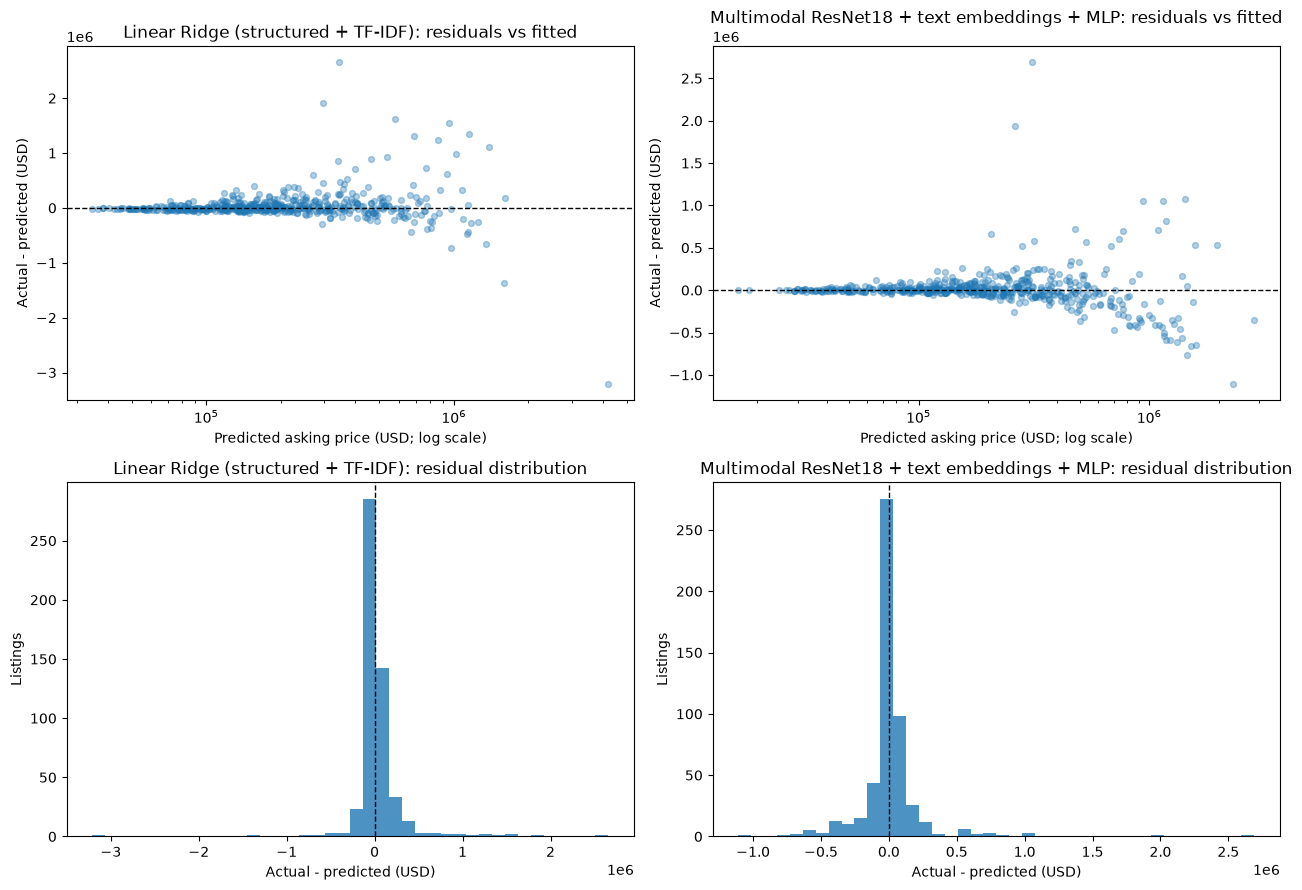

,model,mean_residual_usd,median_residual_usd,p90_absolute_error_usd,p95_absolute_error_usd,spearman_residual_vs_fitted,spearman_p_value
0,Linear Ridge (structured + TF-IDF),39842.220345,-4839.012303,248567.250028,436858.126498,0.074782,0.087238
1,Multimodal ResNet18 + text embeddings + MLP,9774.014373,2490.423828,279056.043750,500973.546875,-0.193647,0.000008


,model,actual_price_band_usd,listings,median_actual_usd,median_predicted_usd,mean_residual_usd,mae_usd
0,Linear Ridge (structured + TF-IDF),"(3999.999, 85000.0]",108,49500.0,77759.913137,-30696.007305,31872.415244
1,Linear Ridge (structured + TF-IDF),"(85000.0, 151000.0]",102,122500.0,136583.959188,-21462.937727,35550.893711
2,Linear Ridge (structured + TF-IDF),"(151000.0, 250000.0]",110,200000.0,179503.298701,-11726.930997,70003.388533
3,Linear Ridge (structured + TF-IDF),"(250000.0, 450000.0]",102,350000.0,284914.713997,39514.062430,107079.116633
4,Linear Ridge (structured + TF-IDF),"(450000.0, 3000000.0]",102,650000.0,533037.530036,231776.862152,373748.700953
5,Multimodal ResNet18 + text embeddings + MLP,"(3999.999, 85000.0]",108,49500.0,49752.720703,-7896.601924,16140.816479
6,Multimodal ResNet18 + text embeddings + MLP,"(85000.0, 151000.0]",102,122500.0,118958.179688,-10066.755630,35289.177275
7,Multimodal ResNet18 + text embeddings + MLP,"(151000.0, 250000.0]",110,200000.0,180081.851562,-5728.731001,58479.412180
8,Multimodal ResNet18 + text embeddings + MLP,"(250000.0, 450000.0]",102,350000.0,305198.203125,8503.617570,101191.332031
9,Multimodal ResNet18 + text embeddings + MLP,"(450000.0, 3000000.0]",102,650000.0,681455.218750,66313.892463,351446.133272


Multimodal MAE change vs Ridge: 9.2% lower
Multimodal RMSE change vs Ridge: 19.8% lower
R2 change vs Ridge: +0.230


In [3]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

test_predictions = results['predictions'].copy()
actual = test_predictions['actual_price_usd'].to_numpy(dtype=float)
model_columns = {
    'Linear Ridge (structured + TF-IDF)': ('linear_predicted_price_usd', 'linear_residual_usd'),
    'Multimodal ResNet18 + text embeddings + MLP': ('multimodal_predicted_price_usd', 'multimodal_residual_usd'),
}
residuals = test_predictions[['listing_id', 'property_url', 'actual_price_usd']].copy()
diagnostic_rows = []
price_band_rows = []
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for column_index, (model_name, (prediction_column, residual_column)) in enumerate(model_columns.items()):
    predicted = test_predictions[prediction_column].to_numpy(dtype=float)
    residual = actual - predicted
    absolute_error = np.abs(residual)
    residuals[residual_column] = residual
    rho = spearmanr(predicted, residual)
    diagnostic_rows.append({
        'model': model_name,
        'mean_residual_usd': residual.mean(),
        'median_residual_usd': np.median(residual),
        'p90_absolute_error_usd': np.quantile(absolute_error, .90),
        'p95_absolute_error_usd': np.quantile(absolute_error, .95),
        'spearman_residual_vs_fitted': rho.statistic,
        'spearman_p_value': rho.pvalue,
    })

    bands = pd.qcut(actual, q=5, duplicates='drop')
    band_data = pd.DataFrame({
        'actual_price_band_usd': bands,
        'actual_price_usd': actual,
        'predicted_price_usd': predicted,
        'residual_usd': residual,
        'absolute_error_usd': absolute_error,
    })
    grouped = band_data.groupby('actual_price_band_usd', observed=True).agg(
        listings=('actual_price_usd', 'size'),
        median_actual_usd=('actual_price_usd', 'median'),
        median_predicted_usd=('predicted_price_usd', 'median'),
        mean_residual_usd=('residual_usd', 'mean'),
        mae_usd=('absolute_error_usd', 'mean'),
    ).reset_index()
    grouped.insert(0, 'model', model_name)
    price_band_rows.append(grouped)

    axes[0, column_index].scatter(predicted, residual, alpha=.35, s=18)
    axes[0, column_index].axhline(0, color='black', linestyle='--', linewidth=1)
    axes[0, column_index].set_xscale('log')
    axes[0, column_index].set(title=f'{model_name}: residuals vs fitted',
                               xlabel='Predicted asking price (USD; log scale)',
                               ylabel='Actual - predicted (USD)')
    axes[1, column_index].hist(residual, bins=40, alpha=.8)
    axes[1, column_index].axvline(0, color='black', linestyle='--', linewidth=1)
    axes[1, column_index].set(title=f'{model_name}: residual distribution',
                               xlabel='Actual - predicted (USD)', ylabel='Listings')

residual_diagnostics = pd.DataFrame(diagnostic_rows)
residuals_by_price_band = pd.concat(price_band_rows, ignore_index=True)
report_dir = PROJECT_ROOT / 'reports' / 'modeling'
residual_diagnostics.to_csv(report_dir / 'residual_diagnostics.csv', index=False)
residuals_by_price_band.to_csv(report_dir / 'residuals_by_actual_price_band.csv', index=False)
residuals.to_csv(report_dir / 'test_residuals.csv', index=False)
fig.tight_layout()
fig.savefig(report_dir / 'residual_diagnostics.png', dpi=160)
plt.show()

display(residual_diagnostics)
display(residuals_by_price_band)
metrics_by_model = results['metrics'].set_index('model')
ridge = metrics_by_model.loc['Linear Ridge (structured + TF-IDF)']
multimodal = metrics_by_model.loc['Multimodal ResNet18 + text embeddings + MLP']
print(f"Multimodal MAE change vs Ridge: {(1 - multimodal['MAE_USD'] / ridge['MAE_USD']):.1%} lower")
print(f"Multimodal RMSE change vs Ridge: {(1 - multimodal['RMSE_USD'] / ridge['RMSE_USD']):.1%} lower")
print(f"R2 change vs Ridge: {multimodal['R2_USD'] - ridge['R2_USD']:+.3f}")

## Interpretation and limitations

Compare MAE, RMSE, and R² on the same held-out test set; lower MAE/RMSE and higher R² are better. RMSE is more sensitive to large misses, so a substantial gap between RMSE and MAE signals a long error tail. Read residuals with the actual-minus-predicted sign convention and the price-band table: a positive mean residual indicates underestimation, and increasing MAE in higher price bands indicates that dollar errors depend on price level.

This is one seeded, price-stratified random split, not repeated cross-validation or an external-market test. Similar locations and listing periods may occur in both train and test splits, so these scores do not establish geographic or future-market generalization. The target is an asking price, not a verified sale price, and the sample is geographically concentrated. Eleven listings lack a readable local photo; the model uses a frozen ImageNet ResNet18 and the first local photo, while its word embedding is learned from the training subset. A few exceptionally large property-area entries are clipped after train-only standardization; this limits their influence but can also compress legitimate extremes. Treat the multimodal model's improvement as promising for this split, not as proof it will outperform on new markets. Validate with repeated or location/time-grouped splits and verified transaction data before using estimates for decisions.